# Nuclei Segmentation: Watershed vs. U-Net

Segmenting cell nuclei in microscopy images from the **2018 Data Science Bowl** (670 training images with masks).

1. Classical baseline: Otsu thresholding + distance transform + marker-based watershed
2. Deep learning: a compact U-Net built from scratch in TensorFlow/Keras
3. Evaluation with Dice coefficient and IoU, plus side-by-side visual comparison

In [ ]:
# List the competition files (Kaggle: data-science-bowl-2018)
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/data-science-bowl-2018/stage1_test.zip
/kaggle/input/data-science-bowl-2018/stage1_sample_submission.csv.zip
/kaggle/input/data-science-bowl-2018/stage2_sample_submission_final.csv.zip
/kaggle/input/data-science-bowl-2018/stage1_train.zip
/kaggle/input/data-science-bowl-2018/stage1_train_labels.csv.zip
/kaggle/input/data-science-bowl-2018/stage1_solution.csv.zip
/kaggle/input/data-science-bowl-2018/stage2_test_final.zip


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread
from skimage.filters import threshold_otsu
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from skimage.morphology import remove_small_objects
from scipy import ndimage as ndi
from zipfile import ZipFile
from sklearn.model_selection import train_test_split
import time
import tensorflow as tf
from tensorflow.keras import layers, models


## 1. Load and preprocess the data

Each image has several per-nucleus masks; they are merged into one binary mask. Images and masks are resized to 256×256 and images are scaled to [0, 1].

In [ ]:
zip_train = "/kaggle/input/data-science-bowl-2018/stage1_train.zip"
extract_path = "/kaggle/working/stage1_train/"

with ZipFile(zip_train, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

image_ids = sorted(os.listdir(extract_path))
print("Number of training images:", len(image_ids))



Number of training images: 670


Resized images shape: (670, 256, 256, 4)
Resized masks shape: (670, 256, 256)


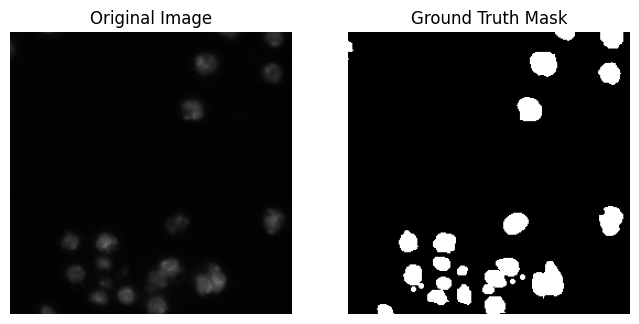

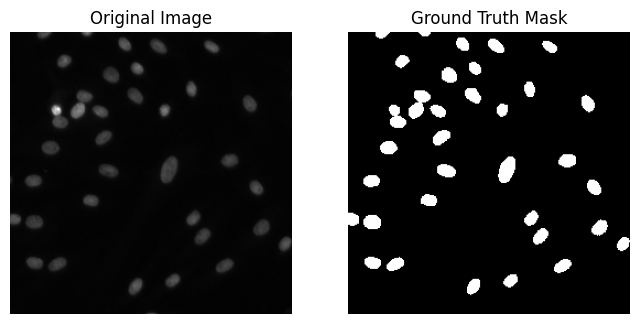

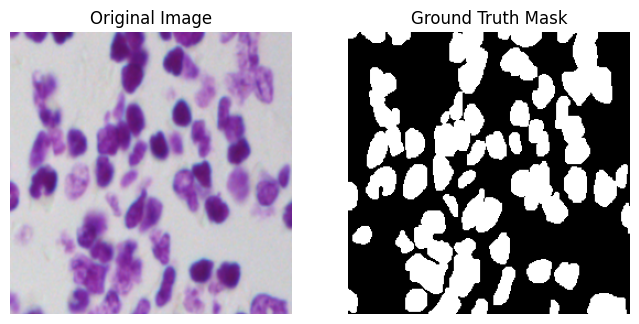

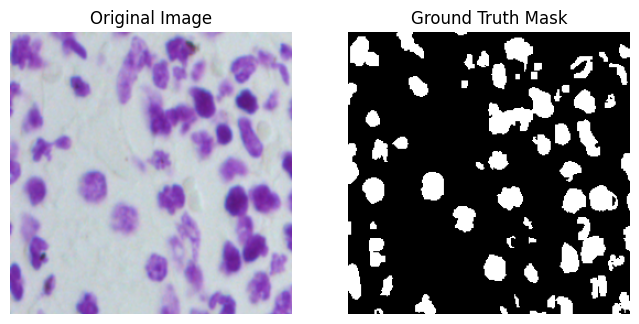

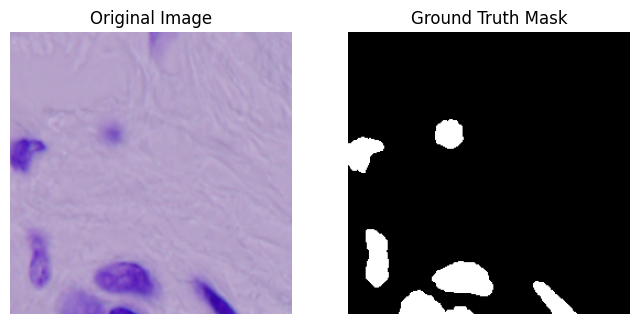

In [ ]:
from skimage.transform import resize

# Target size
IMG_HEIGHT = 256
IMG_WIDTH = 256

# Prepare images and masks
all_images_resized = []
all_masks_resized = []

for img_id in image_ids:
    img_path = os.path.join(extract_path, img_id, "images", img_id + ".png")
    mask_dir = os.path.join(extract_path, img_id, "masks")
    
    image = imread(img_path)
    
    # Merge masks
    mask = np.zeros(image.shape[:2], dtype=np.uint8)
    for m_file in os.listdir(mask_dir):
        mask += imread(os.path.join(mask_dir, m_file)) > 0
    
    # Resize image and mask
    img_resized = resize(image, (IMG_HEIGHT, IMG_WIDTH), preserve_range=True)
    mask_resized = resize(mask, (IMG_HEIGHT, IMG_WIDTH), preserve_range=True, anti_aliasing=False)
    
    # Normalize
    img_resized = img_resized / 255.0
    mask_resized = mask_resized > 0
    
    all_images_resized.append(img_resized)
    all_masks_resized.append(mask_resized)


all_images_resized = np.array(all_images_resized, dtype=np.float32)
all_masks_resized = np.array(all_masks_resized, dtype=np.uint8)

print("Resized images shape:", all_images_resized.shape)
print("Resized masks shape:", all_masks_resized.shape)

# Visualize sample
for i in range(5):
    plt.figure(figsize=(8,4))
    plt.subplot(1,2,1)
    plt.imshow(all_images_resized[i])
    plt.title("Original Image")
    plt.axis("off")
    
    plt.subplot(1,2,2)
    plt.imshow(all_masks_resized[i], cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")
    
    plt.show()


## 2. Evaluation metrics

In [ ]:
import numpy as np

def dice_coef(y_true, y_pred):
    y_true_f = y_true.flatten().astype(np.float32)
    y_pred_f = y_pred.flatten().astype(np.float32)
    intersection = np.sum(y_true_f * y_pred_f)
    return (2. * intersection) / (np.sum(y_true_f) + np.sum(y_pred_f) + 1e-6)

def iou_score(y_true, y_pred):
    y_true_f = y_true.flatten().astype(np.float32)
    y_pred_f = y_pred.flatten().astype(np.float32)
    intersection = np.sum(y_true_f * y_pred_f)
    union = np.sum(y_true_f) + np.sum(y_pred_f) - intersection
    return intersection / (union + 1e-6)


## 3. Classical baseline: Otsu + watershed

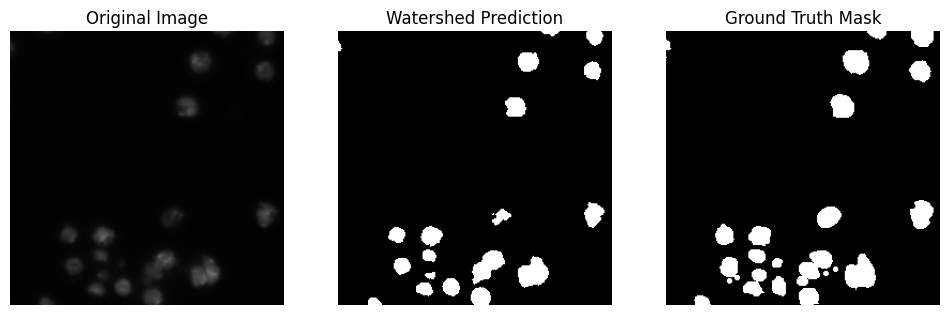

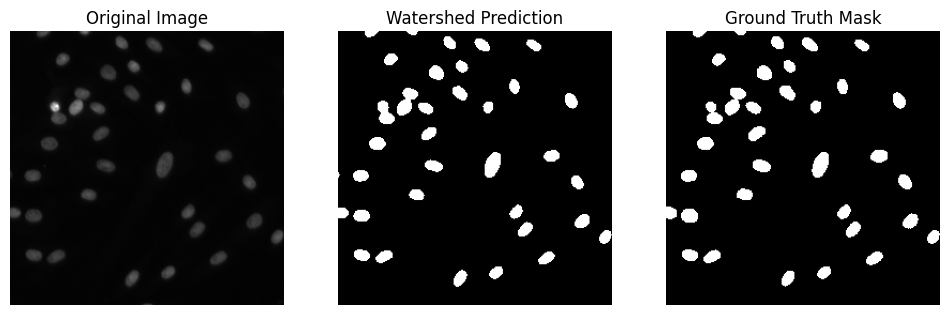

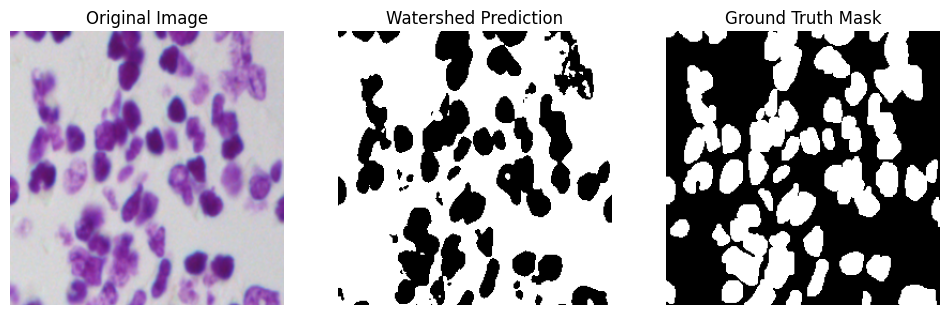

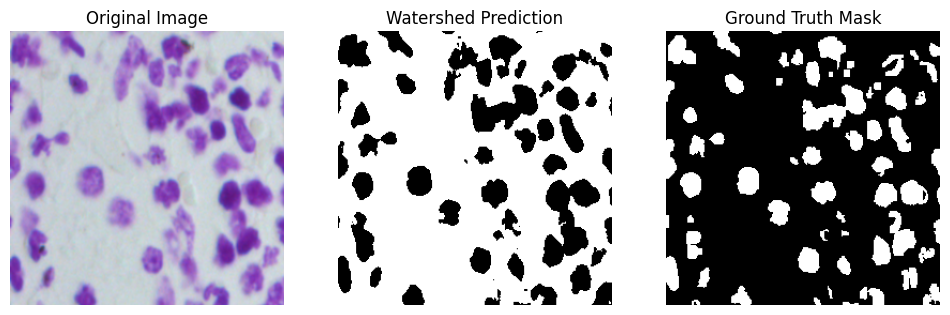

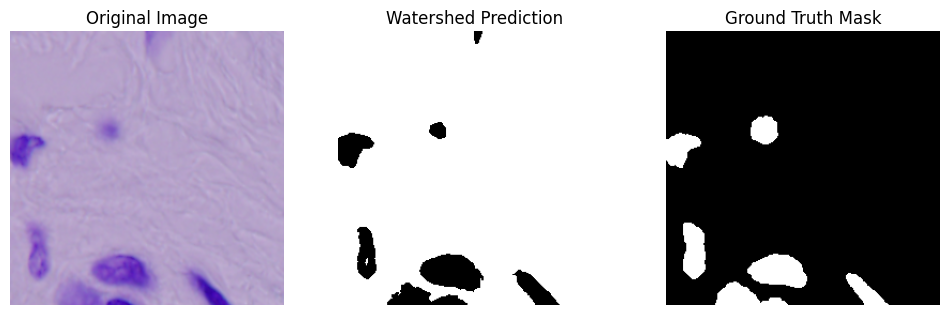

Watershed average Dice: 0.73069364
Watershed average IoU: 0.661665


In [ ]:
watershed_dice = []
watershed_iou = []
watershed_times = []


watershed_predictions = []

for idx in range(len(all_images_resized)):
    image = all_images_resized[idx]
    mask = all_masks_resized[idx]
    
    
    gray = np.mean(image, axis=2)

    # Threshold
    thresh = threshold_otsu(gray)
    binary = gray > thresh
    
    # Distance transform
    distance = ndi.distance_transform_edt(binary)
    
    # Local maxima
    local_max_coords = peak_local_max(
        distance, labels=binary, footprint=np.ones((3,3))
    )
    
    # Markers
    markers = np.zeros_like(distance, dtype=int)
    for i, coord in enumerate(local_max_coords, start=1):
        markers[coord[0], coord[1]] = i
    
    # Watershed
    labels = watershed(-distance, markers, mask=binary)
    pred_mask = labels > 0
    
    
    # Metrics
    dice = dice_coef(mask, pred_mask)
    iou = iou_score(mask, pred_mask)
    
    watershed_dice.append(dice)
    watershed_iou.append(iou)
    
    
    watershed_predictions.append(pred_mask)


num_samples = 5

for i in range(num_samples):
    fig, ax = plt.subplots(1, 3, figsize=(12,4))
    
    ax[0].imshow(all_images_resized[i])
    ax[0].set_title("Original Image")
    ax[0].axis("off")
        
    ax[1].imshow(watershed_predictions[i], cmap="gray")
    ax[1].set_title("Watershed Prediction")
    ax[1].axis("off")
        
    ax[2].imshow(all_masks_resized[i], cmap="gray")
    ax[2].set_title("Ground Truth Mask")
    ax[2].axis("off")
    
    plt.show()

print("Watershed average Dice:", np.mean(watershed_dice))
print("Watershed average IoU:", np.mean(watershed_iou))



## 4. U-Net

Train/validation split (90/10), then a 3-level encoder–decoder U-Net with skip connections, trained with Adam and binary cross-entropy.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    all_images_resized, all_masks_resized, test_size=0.1, random_state=42
)

print("Train set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)


Train set: (603, 256, 256, 4) (603, 256, 256)
Validation set: (67, 256, 256, 4) (67, 256, 256)


In [ ]:
def unet_model(input_size=(256,256,3)):
    inputs = layers.Input(input_size)
    

    c1 = layers.Conv2D(16, 3, activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(16, 3, activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D(2)(c1)
    
    c2 = layers.Conv2D(32, 3, activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(32, 3, activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D(2)(c2)

    c3 = layers.Conv2D(64, 3, activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(64, 3, activation='relu', padding='same')(c3)
    
    u1 = layers.UpSampling2D(2)(c3)
    u1 = layers.concatenate([u1, c2])
    c4 = layers.Conv2D(32, 3, activation='relu', padding='same')(u1)
    c4 = layers.Conv2D(32, 3, activation='relu', padding='same')(c4)
    
    u2 = layers.UpSampling2D(2)(c4)
    u2 = layers.concatenate([u2, c1])
    c5 = layers.Conv2D(16, 3, activation='relu', padding='same')(u2)
    c5 = layers.Conv2D(16, 3, activation='relu', padding='same')(c5)
    
    outputs = layers.Conv2D(1, 1, activation='sigmoid')(c5)
    
    model = models.Model(inputs=[inputs], outputs=[outputs])
    return model

model = unet_model(input_size=X_train.shape[1:])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 256, 256,  │        592 │ input_layer_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 256, 256,  │      2,320 │ conv2d_11[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 128, 128,  │          0 │ conv2d_12[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 128, 128,  │      4,640 │ max_pooling2d_2[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 128, 128,  │      9,248 │ conv2d_13[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 64, 64,    │          0 │ conv2d_14[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 64, 64,    │     36,928 │ conv2d_15[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_2     │ (None, 128, 128,  │          0 │ conv2d_16[0][0]   │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 128, 128,  │          0 │ up_sampling2d_2[… │
│ (Concatenate)       │ 96)               │            │ conv2d_14[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 128, 128,  │     27,680 │ concatenate_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 128, 128,  │      9,248 │ conv2d_17[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_3     │ (None, 256, 256,  │          0 │ conv2d_18[0][0]   │
│ (UpSampling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 256, 256,  │          0 │ up_sampling2d_3[… │
│ (Concatenate)       │ 48)               │            │ conv2d_12[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 256, 256,  │      6,928 │ concatenate_3[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 256, 256,  │      2,320 │ conv2d_19[0][0] 

 Total params: 118,417 (462.57 KB)

 Trainable params: 118,417 (462.57 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train, y_train[..., np.newaxis],
    validation_data=(X_val, y_val[..., np.newaxis]),
    batch_size=8,
    epochs=20
)


Epoch 1/20


I0000 00:00:1767384141.531094     166 service.cc:152] XLA service 0x7a1efc0483f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1767384141.531134     166 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1767384142.208921     166 cuda_dnn.cc:529] Loaded cuDNN version 91002


 5/76 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.8377 - loss: 0.6773

I0000 00:00:1767384147.581982     166 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


76/76 ━━━━━━━━━━━━━━━━━━━━ 17s 112ms/step - accuracy: 0.8511 - loss: 0.4713 - val_accuracy: 0.8668 - val_loss: 0.2539
Epoch 2/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.8725 - loss: 0.2561 - val_accuracy: 0.9331 - val_loss: 0.1519
Epoch 3/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9440 - loss: 0.1428 - val_accuracy: 0.9539 - val_loss: 0.1144
Epoch 4/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9518 - loss: 0.1207 - val_accuracy: 0.9603 - val_loss: 0.1046
Epoch 5/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9577 - loss: 0.1069 - val_accuracy: 0.9649 - val_loss: 0.0892
Epoch 6/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9602 - loss: 0.0990 - val_accuracy: 0.9674 - val_loss: 0.0845
Epoch 7/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9632 - loss: 0.0938 - val_accuracy: 0.9685 - val_loss: 0.0790
Epoch 8/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9648 - loss: 0.0877 - val_accuracy: 0.9682 - val_loss: 

## 5. U-Net evaluation on the validation set

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 857ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━

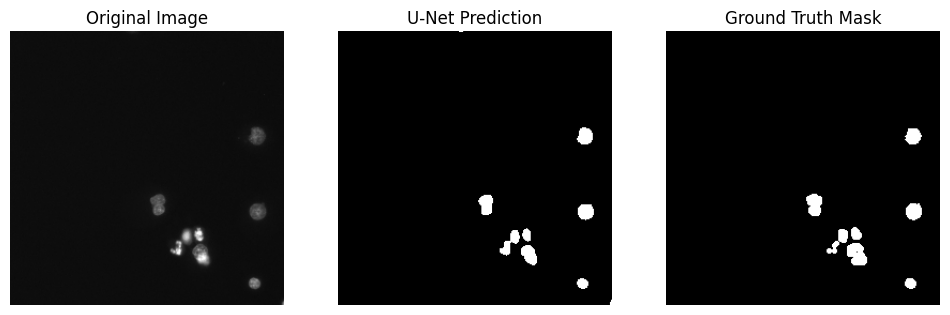

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


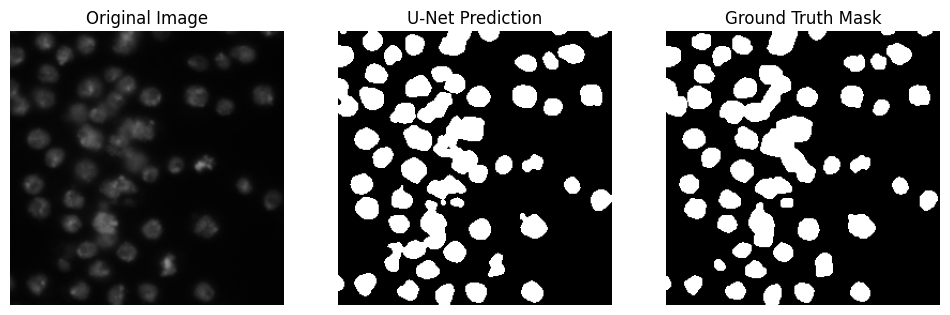

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


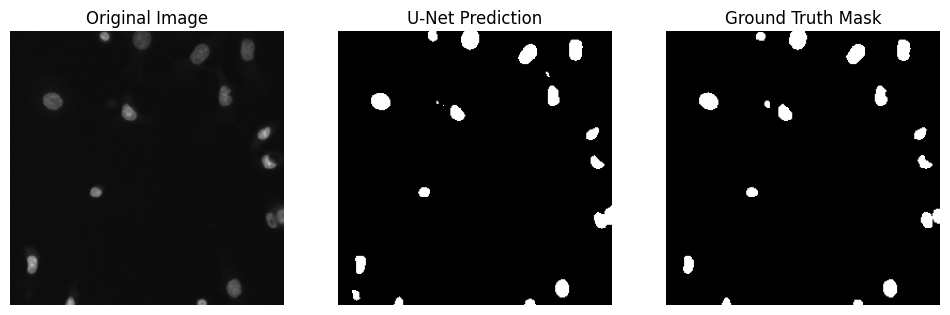

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


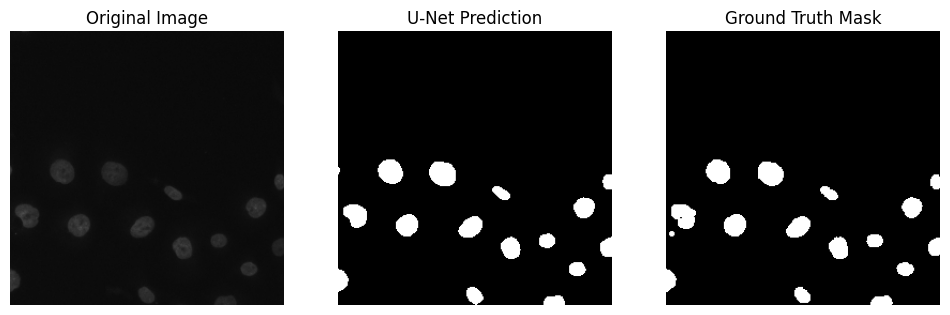

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


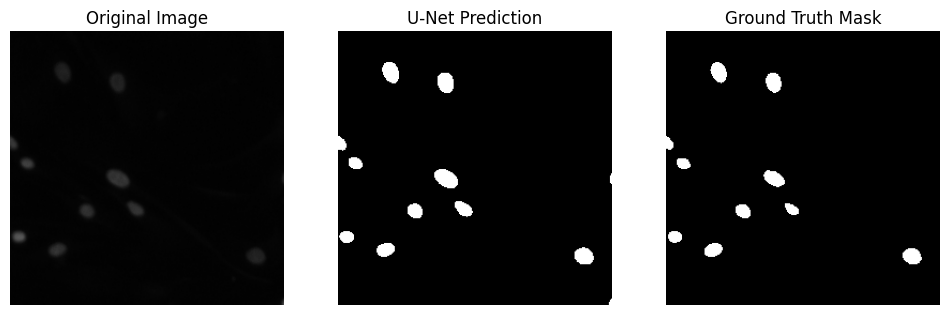

U-Net average Dice: 0.88384414
U-Net average IoU: 0.811211


In [ ]:
unet_dice = []
unet_iou = []

for idx in range(len(X_val)):
    image = X_val[idx]
    mask = y_val[idx]
    
    pred_mask = model.predict(image[np.newaxis,...])[0,...,0]
    pred_mask_bin = pred_mask > 0.5
    
    dice = dice_coef(mask, pred_mask_bin)
    iou = iou_score(mask, pred_mask_bin)
    unet_dice.append(dice)
    unet_iou.append(iou)
    
# Visualize 5 samples
for idx in range(5):
    image = X_val[idx]
    mask = y_val[idx]
    pred_mask = model.predict(image[np.newaxis,...])[0,...,0]
    pred_mask_bin = pred_mask > 0.5
    
    fig, ax = plt.subplots(1,3, figsize=(12,4))
    ax[0].imshow(image)
    ax[0].set_title("Original Image")
    ax[0].axis("off")
    
    ax[1].imshow(pred_mask_bin, cmap="gray")
    ax[1].set_title("U-Net Prediction")
    ax[1].axis("off")
    
    ax[2].imshow(mask, cmap="gray")
    ax[2].set_title("Ground Truth Mask")
    ax[2].axis("off")
    plt.show()

print("U-Net average Dice:", np.mean(unet_dice))
print("U-Net average IoU:", np.mean(unet_iou))


## 6. Side-by-side comparison: image, watershed, U-Net, ground truth

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


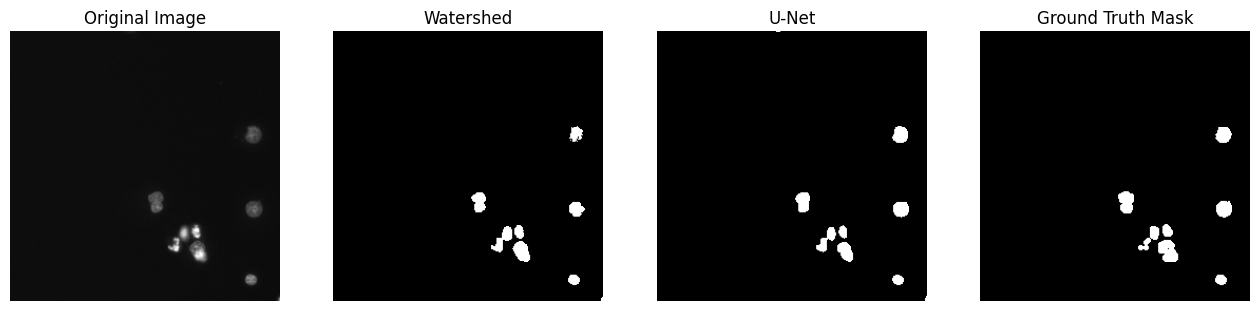

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


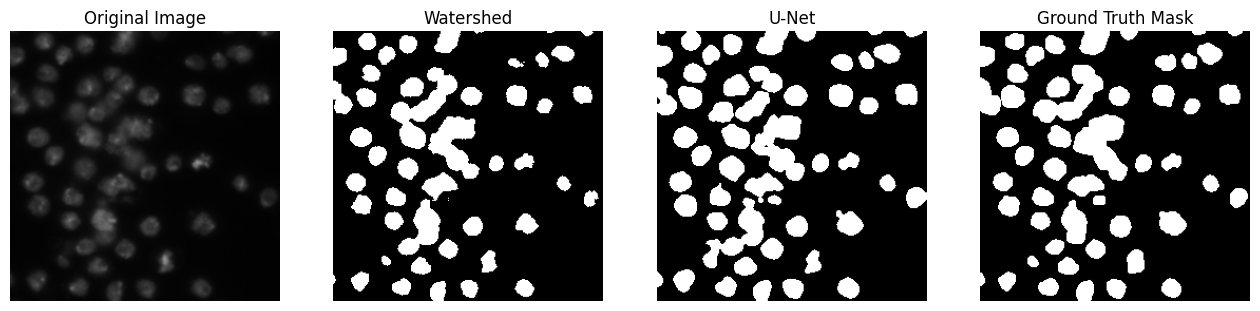

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


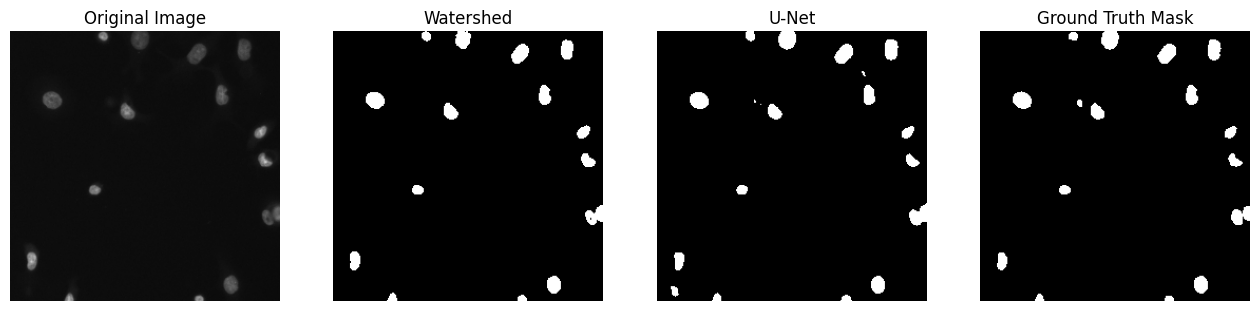

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


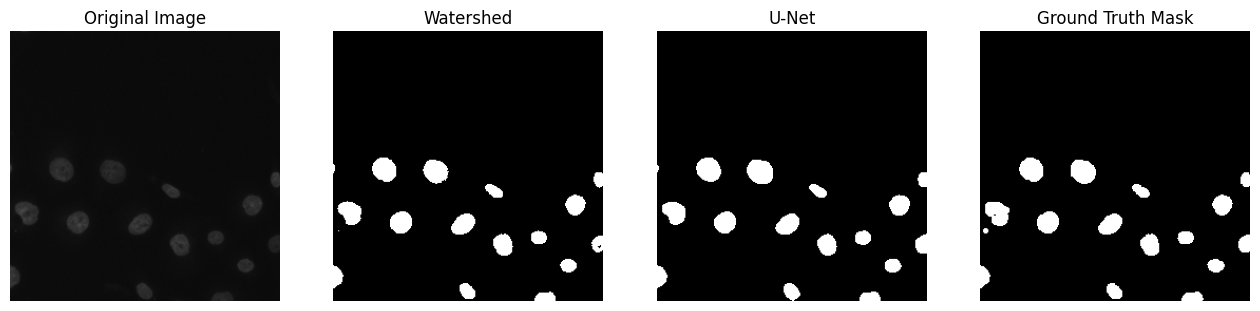

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


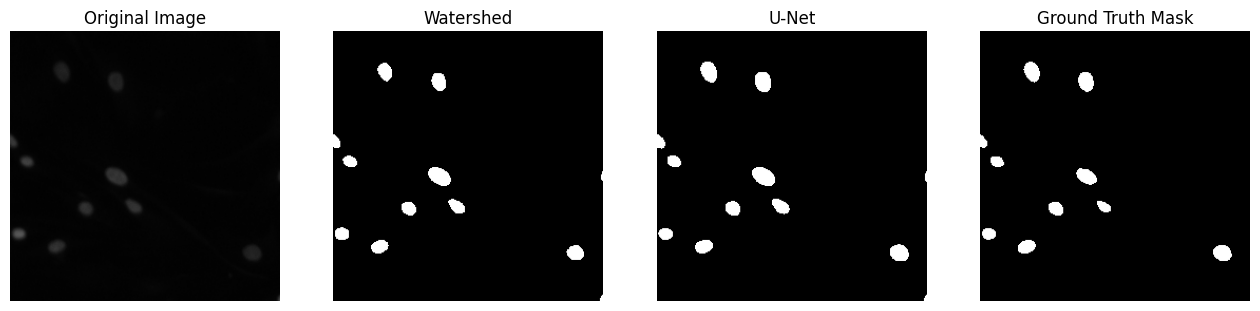

In [ ]:
for idx in range(5):
    image = X_val[idx]
    mask = y_val[idx]
    
    # Watershed prediction
    gray = np.mean(image, axis=2)
    thresh = threshold_otsu(gray)
    binary = gray > thresh
    distance = ndi.distance_transform_edt(binary)
    local_max_coords = peak_local_max(distance, labels=binary, footprint=np.ones((3,3)))
    markers = np.zeros_like(distance, dtype=int)
    for i, coord in enumerate(local_max_coords, start=1):
        markers[coord[0], coord[1]] = i
    ws_pred = watershed(-distance, markers, mask=binary) > 0
    
    # U-Net prediction
    unet_pred = model.predict(image[np.newaxis,...])[0,...,0] > 0.5
    
    fig, ax = plt.subplots(1,4, figsize=(16,4))
    ax[0].imshow(image)
    ax[0].set_title("Original Image")
    ax[0].axis("off")
    
    ax[1].imshow(ws_pred, cmap="gray")
    ax[1].set_title("Watershed")
    ax[1].axis("off")
    
    ax[2].imshow(unet_pred, cmap="gray")
    ax[2].set_title("U-Net")
    ax[2].axis("off")
    
    ax[3].imshow(mask, cmap="gray")
    ax[3].set_title("Ground Truth Mask")
    ax[3].axis("off")
    
    plt.show()
